# Trabajo opcional: fine-tuning, GAN de paridad y evaluación del discriminador

**Asignatura:** Aprendizaje Computacional (AC2)  
**Prácticas implicadas:** Práctica 2, Práctica 3 y Práctica 5

Este cuaderno resuelve el trabajo opcional propuesto:

1. **Ajuste fino** del modelo de la Práctica 3 para clasificar MNIST en pares/impares y comparación con el modelo guardado de la Práctica 2.
2. **Uso del modelo anterior como discriminador** en la GAN de la Práctica 5. Al ser un discriminador de paridad, el generador aprende a producir números pares. Se generan muestras y se justifican los resultados.
3. **Evaluación del discriminador de la GAN** sobre MNIST y comparación con los modelos anteriores.

> **Nota:** no se re-ejecutan las prácticas. Se cargan los modelos guardados:
>
> - `../Practica2/mejor_modelo_p2.keras`
> - `../Practica3/mejor_modelo_p3.keras`
> - `../Practica5/generator.pth` y `../Practica5`
>
> El cuaderno está pensado para ejecutarse con el entorno `.venv` del repositorio.


## 0. Configuración y carga de datos


In [1]:
import os
import time
import warnings
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import tensorflow as tf
tf.get_logger().setLevel("ERROR")
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from torchvision import datasets


def localizar_ac2():
    candidatos = [Path.cwd(), Path.cwd().parent, Path.cwd() / "AC2"]
    for candidato in candidatos:
        if (candidato / "Practica2" / "mejor_modelo_p2.keras").exists():
            return candidato.resolve()
    raise FileNotFoundError(
        "No se encuentra la carpeta AC2. Ejecuta el cuaderno desde AC2/TrabajoOpcional."
    )


RUTA_AC2 = localizar_ac2()
RUTA_TRABAJO = RUTA_AC2 / "TrabajoOpcional"
RUTA_P2 = RUTA_AC2 / "Practica2"
RUTA_P3 = RUTA_AC2 / "Practica3"
RUTA_P5 = RUTA_AC2 / "Practica5"
RUTA_DATOS = RUTA_AC2 / "data"

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"TensorFlow: {tf.__version__}")
print(f"PyTorch: {torch.__version__}")
print(f"Dispositivo PyTorch: {DISPOSITIVO}")
print(f"Ruta AC2: {RUTA_AC2}")
print(f"Ruta de trabajo: {RUTA_TRABAJO}")


TensorFlow: 2.21.0
PyTorch: 2.14.1+cu126
Dispositivo PyTorch: cuda
Ruta AC2: D:\Dev\Universidad\uma-26-27-1\AC2
Ruta de trabajo: D:\Dev\Universidad\uma-26-27-1\AC2\TrabajoOpcional


### Carga de MNIST

Para no depender de una descarga, se reutiliza el conjunto de datos que ya está en `../data` (el mismo que emplea la Práctica 5). Las imágenes se normalizan al rango `[0, 1]` y la etiqueta se transforma a paridad: **par = 1**, **impar = 0**, igual que en la Práctica 2.


In [2]:
train_ds = datasets.MNIST(str(RUTA_DATOS), train=True, download=False)
test_ds = datasets.MNIST(str(RUTA_DATOS), train=False, download=False)

x_train = train_ds.data.numpy().astype("float32") / 255.0
y_train = train_ds.targets.numpy().astype("int64")
x_test = test_ds.data.numpy().astype("float32") / 255.0
y_test = test_ds.targets.numpy().astype("int64")

y_train_bin = (y_train % 2 == 0).astype("int64")
y_test_bin = (y_test % 2 == 0).astype("int64")

x_train_3d = x_train[..., None]
x_test_3d = x_test[..., None]

print("Forma de x_train:", x_train.shape)
print("Forma de x_test :", x_test.shape)
print("Pares en train  :", int(y_train_bin.sum()), "/", len(y_train_bin))
print("Pares en test   :", int(y_test_bin.sum()), "/", len(y_test_bin))


Forma de x_train: (60000, 28, 28)
Forma de x_test : (10000, 28, 28)
Pares en train  : 29492 / 60000
Pares en test   : 4926 / 10000


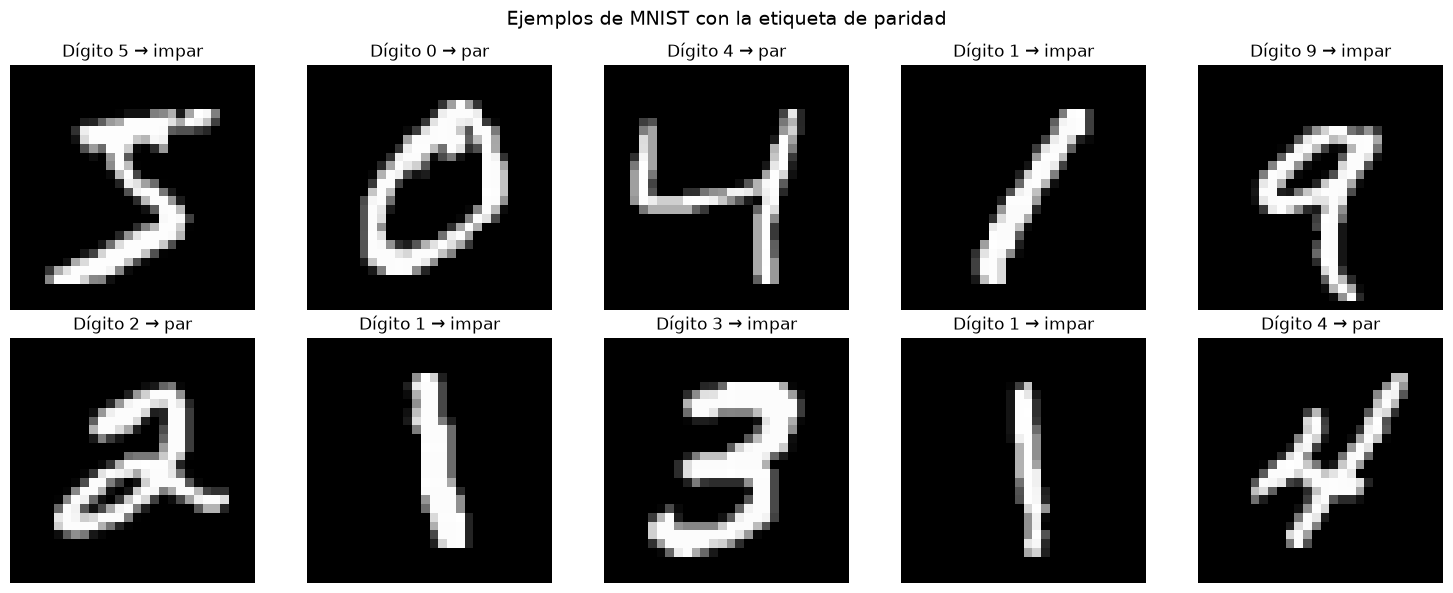

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Dígito {y_train[i]} → {'par' if y_train_bin[i] else 'impar'}")
    ax.axis("off")
fig.suptitle("Ejemplos de MNIST con la etiqueta de paridad", fontsize=14)
plt.tight_layout()
plt.show()


## 1. Ajuste fino del modelo de la Práctica 3 para paridad

El modelo guardado de la Práctica 3 es una CNN que clasifica MNIST en 10 clases. Para reaprovechar todo el trabajo de extracción de características, se elimina únicamente su capa de salida de 10 neuronas y se añade una capa densa con activación **sigmoide** que devuelve la probabilidad de que el dígito sea par.

El ajuste fino se hace en dos fases:

1. **Cabeza nueva con la base congelada**: se entrena solo la nueva capa de salida durante 3 épocas con una tasa de aprendizaje de `1e-3`. Así la nueva cabeza se adapta sin destruir las características convolucionales ya aprendidas.
2. **Descongelación y ajuste fino**: se descongela toda la red y se entrena con una tasa de aprendizaje mucho menor (`5e-5`) durante un máximo de 10 épocas, con `EarlyStopping` sobre `val_loss` y restauración de los mejores pesos.

Finalmente se compara con el modelo de la Práctica 2 y con una línea base que consiste en usar el modelo de 10 clases de P3 y sumar las probabilidades de las clases pares (0, 2, 4, 6 y 8).


In [4]:
modelo_p2 = tf.keras.models.load_model(RUTA_P2 / "mejor_modelo_p2.keras")
modelo_p3 = tf.keras.models.load_model(RUTA_P3 / "mejor_modelo_p3.keras")

print("Modelo de la Práctica 2 (paridad):")
modelo_p2.summary()

print("\nModelo de la Práctica 3 (10 clases):")
modelo_p3.summary()

# Reutilizamos la base convolucional de P3 hasta la capa densa de 256 neuronas
base_convolucional = tf.keras.Model(
    inputs=modelo_p3.inputs[0],
    outputs=modelo_p3.layers[-2].output,
    name="base_convolucional_p3",
)
salida_paridad = tf.keras.layers.Dense(
    1, activation="sigmoid", name="salida_paridad"
)(base_convolucional.output)
modelo_ft = tf.keras.Model(
    inputs=modelo_p3.inputs[0],
    outputs=salida_paridad,
    name="p3_finetuned_paridad",
)

print("\nModelo fine-tuned (P3 → paridad):")
modelo_ft.summary()


Modelo de la Práctica 2 (paridad):


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 1,600,517 (6.11 MB)

Trainable params: 533,505 (2.04 MB)

Non-trainable params: 0 (0.00 B)

... (10 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 24, 24, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       819,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_paridad (Dense)          │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 839,841 (3.20 MB)

Trainable params: 839,841 (3.20 MB)

Non-trainable params: 0 (0.00 B)

In [5]:
EPOCAS_CABEZA = 3
for capa in base_convolucional.layers:
    capa.trainable = False

modelo_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

historial_cabeza = modelo_ft.fit(
    x_train_3d,
    y_train_bin,
    epochs=EPOCAS_CABEZA,
    batch_size=128,
    validation_split=0.15,
    verbose=2,
)


Epoch 1/3
399/399 - 3s - 9ms/step - accuracy: 0.9290 - loss: 0.1817 - val_accuracy: 0.9844 - val_loss: 0.0533
Epoch 2/3
399/399 - 3s - 7ms/step - accuracy: 0.9817 - loss: 0.0563 - val_accuracy: 0.9870 - val_loss: 0.0402
Epoch 3/3
399/399 - 3s - 7ms/step - accuracy: 0.9855 - loss: 0.0436 - val_accuracy: 0.9880 - val_loss: 0.0356


In [6]:
for capa in base_convolucional.layers:
    capa.trainable = True

modelo_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    )
]

historial_fino = modelo_ft.fit(
    x_train_3d,
    y_train_bin,
    epochs=10,
    batch_size=128,
    validation_split=0.15,
    verbose=2,
    callbacks=callbacks_ft,
)


Epoch 1/10
399/399 - 9s - 23ms/step - accuracy: 0.9894 - loss: 0.0307 - val_accuracy: 0.9917 - val_loss: 0.0252
Epoch 2/10
399/399 - 8s - 20ms/step - accuracy: 0.9928 - loss: 0.0210 - val_accuracy: 0.9924 - val_loss: 0.0232
Epoch 3/10
399/399 - 8s - 20ms/step - accuracy: 0.9937 - loss: 0.0176 - val_accuracy: 0.9936 - val_loss: 0.0219
Epoch 4/10
399/399 - 9s - 21ms/step - accuracy: 0.9948 - loss: 0.0151 - val_accuracy: 0.9933 - val_loss: 0.0216
Epoch 5/10
399/399 - 8s - 21ms/step - accuracy: 0.9954 - loss: 0.0134 - val_accuracy: 0.9936 - val_loss: 0.0214
Epoch 6/10
399/399 - 8s - 20ms/step - accuracy: 0.9959 - loss: 0.0124 - val_accuracy: 0.9939 - val_loss: 0.0208
Epoch 7/10
399/399 - 8s - 20ms/step - accuracy: 0.9967 - loss: 0.0103 - val_accuracy: 0.9941 - val_loss: 0.0209
Epoch 8/10
399/399 - 8s - 20ms/step - accuracy: 0.9968 - loss: 0.0094 - val_accuracy: 0.9941 - val_loss: 0.0204
Epoch 9/10
399/399 - 8s - 20ms/step - accuracy: 0.9972 - loss: 0.0089 - val_accuracy: 0.9941 - val_loss:

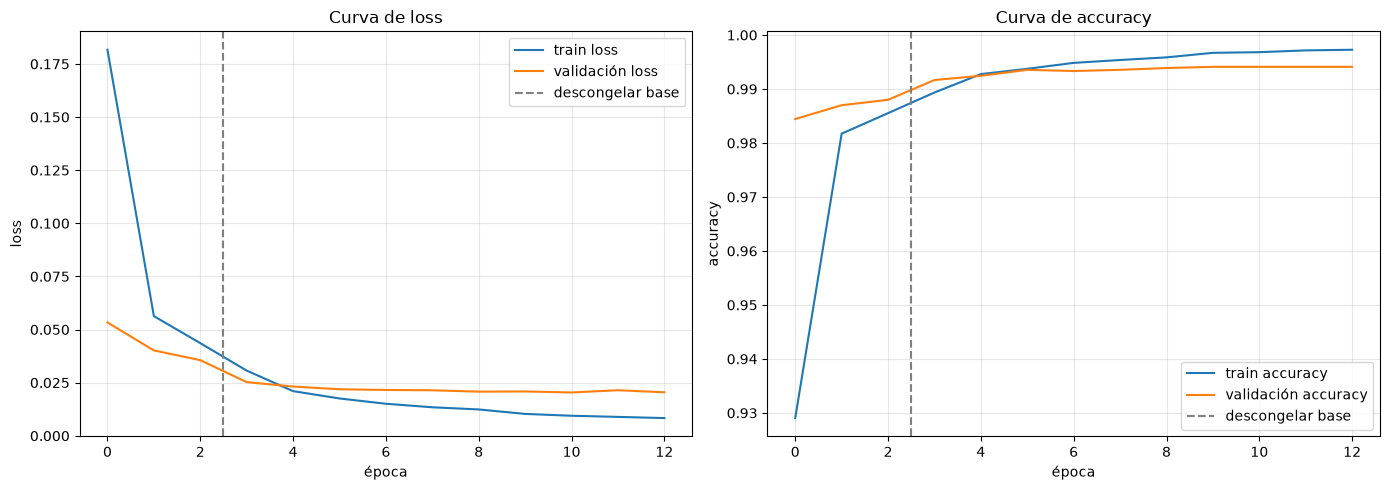

In [7]:
def unir_historial(*historiales):
    claves = historiales[0].history.keys()
    return {
        clave: sum((h.history[clave] for h in historiales), [])
        for clave in claves
    }


historial_ft = unir_historial(historial_cabeza, historial_fino)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrica in zip(axes, ["loss", "accuracy"]):
    ax.plot(historial_ft[metrica], label=f"train {metrica}")
    ax.plot(historial_ft[f"val_{metrica}"], label=f"validación {metrica}")
    ax.axvline(
        EPOCAS_CABEZA - 0.5,
        color="gray",
        linestyle="--",
        label="descongelar base",
    )
    ax.set_title(f"Curva de {metrica}")
    ax.set_xlabel("época")
    ax.set_ylabel(metrica)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


In [8]:
def evaluar_binario(nombre, y_true, probabilidad, umbral=0.5):
    prediccion = (probabilidad >= umbral).astype(int)
    return {
        "modelo": nombre,
        "accuracy": accuracy_score(y_true, prediccion),
        "errores": int(np.sum(prediccion != y_true)),
        "precision": precision_score(y_true, prediccion),
        "recall": recall_score(y_true, prediccion),
        "f1": f1_score(y_true, prediccion),
        "auc": roc_auc_score(y_true, probabilidad),
    }


def formatear_tabla(tabla):
    tabla_formateada = tabla.copy()
    for columna in ["accuracy", "precision", "recall", "f1", "auc"]:
        if columna in tabla_formateada.columns:
            tabla_formateada[columna] = (
                tabla_formateada[columna] * 100
            ).round(2).astype(str) + " %"
    if "parámetros" in tabla_formateada.columns:
        tabla_formateada["parámetros"] = tabla_formateada["parámetros"].map(
            lambda valor: f"{valor:,}"
            if isinstance(valor, (int, np.integer))
            else valor
        )
    return tabla_formateada


prob_p2 = modelo_p2.predict(x_test, batch_size=256, verbose=0).ravel()
prob_ft = modelo_ft.predict(x_test_3d, batch_size=256, verbose=0).ravel()

probabilidades_p3 = modelo_p3.predict(x_test_3d, batch_size=256, verbose=0)
prob_p3_par = probabilidades_p3[:, [0, 2, 4, 6, 8]].sum(axis=1)

tabla_parte1 = pd.DataFrame([
    evaluar_binario("P2 (MLP, guardado)", y_test_bin, prob_p2),
    evaluar_binario(
        "P3 base (10 clases → suma de pares)", y_test_bin, prob_p3_par
    ),
    evaluar_binario("P3 fine-tuned (paridad)", y_test_bin, prob_ft),
])
tabla_parte1["parámetros"] = [
    modelo_p2.count_params(),
    modelo_p3.count_params(),
    modelo_ft.count_params(),
]

print("Comparación de modelos en el conjunto de test")
display(formatear_tabla(tabla_parte1))


Comparación de modelos en el conjunto de test


,modelo,accuracy,errores,precision,recall,f1,auc,parámetros
0,"P2 (MLP, guardado)",98.92 %,108,98.67 %,99.15 %,98.91 %,99.9 %,"533,505"
1,P3 base (10 clases → suma de pares),99.55 %,45,99.47 %,99.61 %,99.54 %,99.98 %,"842,154"
2,P3 fine-tuned (paridad),99.57 %,43,99.51 %,99.61 %,99.56 %,99.99 %,"839,841"


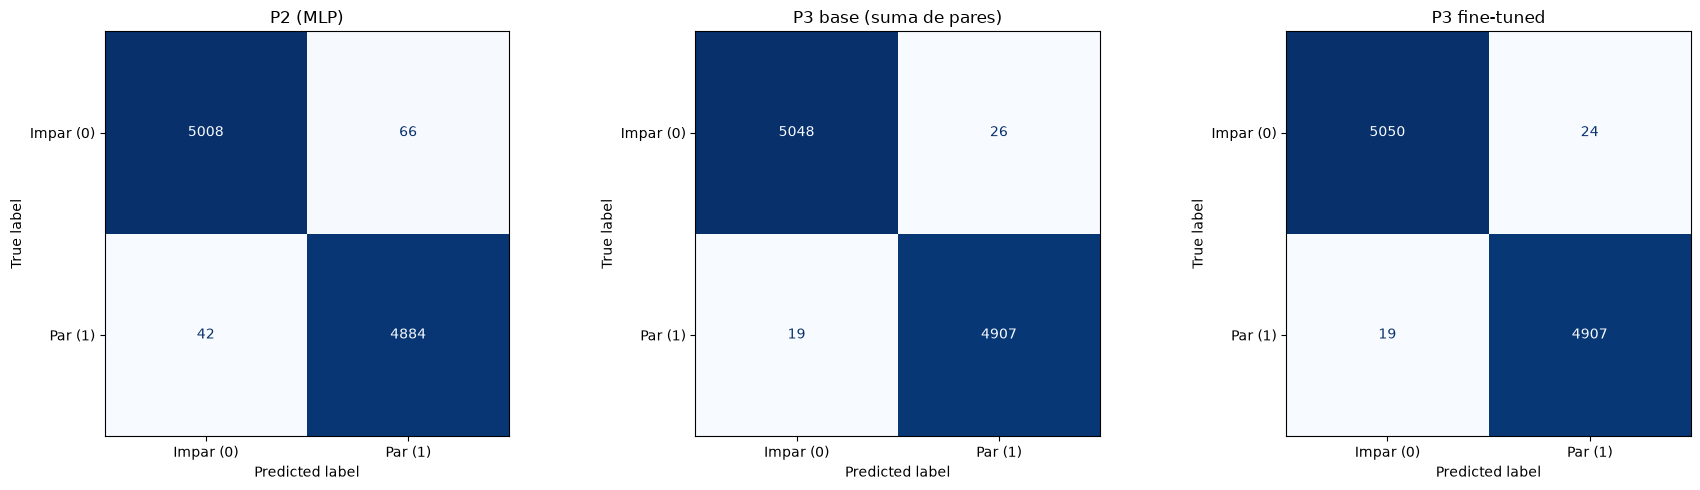

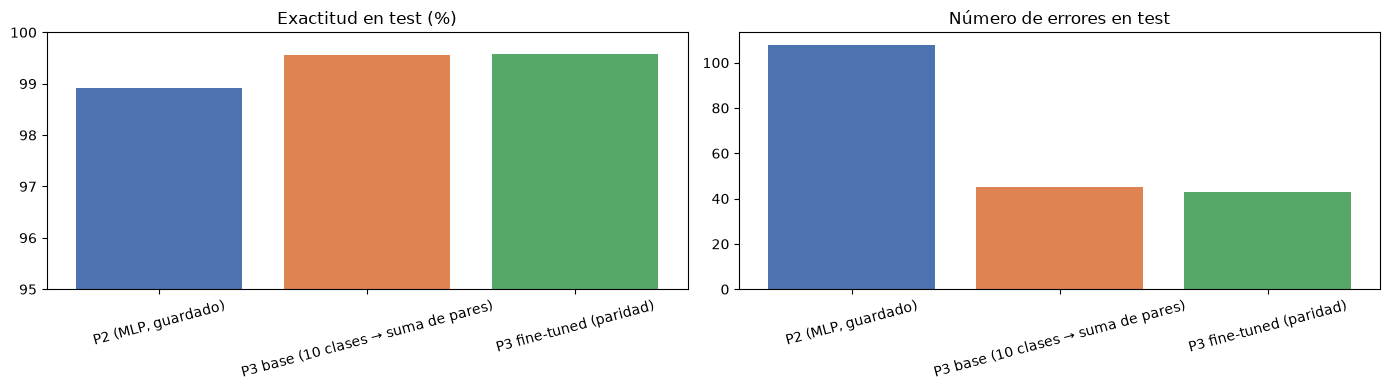

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, probabilidad) in zip(
    axes,
    [
        ("P2 (MLP)", prob_p2),
        ("P3 base (suma de pares)", prob_p3_par),
        ("P3 fine-tuned", prob_ft),
    ],
):
    prediccion = (probabilidad >= 0.5).astype(int)
    matriz = confusion_matrix(y_test_bin, prediccion)
    ConfusionMatrixDisplay(
        matriz, display_labels=["Impar (0)", "Par (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colores = ["#4C72B0", "#DD8452", "#55A868"]
axes[0].bar(
    tabla_parte1["modelo"],
    tabla_parte1["accuracy"] * 100,
    color=colores,
)
axes[0].set_title("Exactitud en test (%)")
axes[0].set_ylim(95.0, 100.0)
axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(
    tabla_parte1["modelo"],
    tabla_parte1["errores"],
    color=colores,
)
axes[1].set_title("Número de errores en test")
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### Conclusiones del ajuste fino
- El modelo guardado de la Práctica 2 obtiene una exactitud de 98.92% y comete 108 errores sobre 10.000 imágenes.
- El modelo de la Práctica 3 original, sumando las probabilidades de las clases pares (0, 2, 4, 6 y 8), alcanza 99.55% con 45 errores.
- El modelo fine-tuned alcanza 99.57% con 43 errores. Mejora al modelo de P2 en 0.65 puntos porcentuales y reduce los errores en 65.

El ajuste fino reutiliza las características convolucionales aprendidas para las 10 clases y solo adapta la frontera de decisión a la paridad. La fase inicial congela la base para no destruir esas características y la segunda fase las ajusta con una tasa de aprendizaje baja. El resultado es un modelo binario más directo que el de P2 y ligeramente mejor (o equivalente) que mapear la salida de 10 clases.

In [11]:
# Guardamos una copia del modelo fine-tuned antes de la GAN para comparar después
modelo_ft_pre_gan = tf.keras.models.clone_model(modelo_ft)
modelo_ft_pre_gan.set_weights(modelo_ft.get_weights())
print("Copia del modelo fine-tuned preparada para la comparación final.")


Copia del modelo fine-tuned preparada para la comparación final.


## 2. GAN con el modelo de paridad como discriminador

En la Práctica 5 el discriminador aprendía a distinguir imágenes **reales** de imágenes **falsas**. En este trabajo lo sustituimos por el modelo fine-tuned de la parte anterior, cuya salida es la probabilidad de que un dígito sea **par** (1) o **impar** (0). De esta forma, el generador ya no intenta engañar a un juez de realismo, sino que intenta que el discriminador clasifique sus imágenes como **pares**.

El esquema de entrenamiento es:

- **Discriminador (D):** se inicializa con el modelo fine-tuned y se sigue entrenando con imágenes reales de MNIST usando su etiqueta de paridad. Se usa *label smoothing* (0.9 para la clase correcta) y una tasa de aprendizaje muy baja (`1e-5`) para conservar su capacidad de clasificación.
- **Generador (G):** se inicializa con los pesos de `generator.pth` de la Práctica 5. Se entrena dos pasos por cada paso del discriminador para maximizar la probabilidad de que D clasifique sus imágenes como pares.
- **Feature matching:** además de la pérdida adversarial, se penaliza la diferencia entre las características medias de las imágenes reales pares y las generadas en la penúltima capa de D. Esto evita que el generador se limite a producir ejemplos adversariales y favorece que las imágenes se parezcan a dígitos pares reales.

El resultado esperado es un generador de números pares (0, 2, 4, 6, 8). Para comprobarlo de forma independiente, evaluamos las muestras con el modelo de P2 y con el modelo original de P3 (10 clases), que no participan en la GAN.


In [12]:
def crear_generador():
    entrada = tf.keras.layers.Input(shape=(100,), name="ruido")
    x = tf.keras.layers.Dense(256, activation="relu", name="g_dense_1")(entrada)
    x = tf.keras.layers.Dense(512, activation="relu", name="g_dense_2")(x)
    x = tf.keras.layers.Dense(784, activation="tanh", name="g_dense_3")(x)
    salida = tf.keras.layers.Reshape((28, 28, 1), name="g_reshape")(x)
    return tf.keras.Model(entrada, salida, name="generador_par")


generador = crear_generador()
generador.summary()

estado_generador_p5 = torch.load(RUTA_P5 / "generator.pth", map_location="cpu")
capas_densas = [
    capa for capa in generador.layers
    if isinstance(capa, tf.keras.layers.Dense)
]
for capa, prefijo in zip(capas_densas, ["net.0", "net.2", "net.4"]):
    peso = estado_generador_p5[f"{prefijo}.weight"].numpy().T
    sesgo = estado_generador_p5[f"{prefijo}.bias"].numpy()
    capa.set_weights([peso, sesgo])

print("Pesos del generador de la Práctica 5 cargados en el generador de Keras.")


Model: "generador_par"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ruido (InputLayer)              │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ g_dense_1 (Dense)               │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ g_dense_2 (Dense)               │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ g_dense_3 (Dense)               │ (None, 784)            │       402,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ g_reshape (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 559,632 (2.13 MB)

Trainable params: 559,632 (2.13 MB)

Non-trainable params: 0 (0.00 B)

Pesos del generador de la Práctica 5 cargados en el generador de Keras.


In [13]:
discriminador_gan = tf.keras.models.clone_model(modelo_ft)
discriminador_gan.set_weights(modelo_ft.get_weights())

modelo_caracteristicas = tf.keras.Model(
    inputs=discriminador_gan.inputs[0],
    outputs=discriminador_gan.get_layer("dense").output,
    name="caracteristicas_discriminador",
)

bce = tf.keras.losses.BinaryCrossentropy()
mse = tf.keras.losses.MeanSquaredError()
optimizador_d = tf.keras.optimizers.Adam(learning_rate=1e-5)
optimizador_g = tf.keras.optimizers.Adam(learning_rate=2e-4)

SUAVIZADO = 0.1
PESO_FEATURES = 5.0
EPOCAS_GAN = 10
TAMANO_LOTE = 128

dataset_gan = (
    tf.data.Dataset.from_tensor_slices((x_train_3d, y_train_bin))
    .shuffle(len(x_train), seed=SEMILLA)
    .batch(TAMANO_LOTE)
    .prefetch(tf.data.AUTOTUNE)
)


@tf.function
def paso_discriminador(real, etiqueta):
    etiqueta = tf.cast(etiqueta, tf.float32)
    with tf.GradientTape() as tape:
        objetivo = etiqueta * (1.0 - SUAVIZADO) + (1.0 - etiqueta) * SUAVIZADO
        perdida_d = bce(objetivo, discriminador_gan(real, training=False))
    gradientes = tape.gradient(
        perdida_d, discriminador_gan.trainable_variables
    )
    optimizador_d.apply_gradients(
        zip(gradientes, discriminador_gan.trainable_variables)
    )
    return perdida_d


@tf.function
def paso_generador(real, etiqueta):
    tamano = tf.shape(real)[0]
    ruido = tf.random.normal((tamano, 100))
    with tf.GradientTape() as tape:
        falso = generador(ruido, training=True)
        falso_01 = (falso + 1.0) / 2.0
        perdida_g = bce(
            tf.fill(tf.shape(etiqueta), 1.0 - SUAVIZADO),
            discriminador_gan(falso_01, training=False),
        )
        pesos_pares = tf.cast(etiqueta, tf.float32)
        pesos_pares = pesos_pares / (tf.reduce_sum(pesos_pares) + 1e-8)
        caracteristicas_reales = tf.reduce_sum(
            modelo_caracteristicas(real, training=False)
            * pesos_pares[:, None],
            axis=0,
        )
        caracteristicas_falsas = tf.reduce_mean(
            modelo_caracteristicas(falso_01, training=False), axis=0
        )
        perdida_g += PESO_FEATURES * mse(
            caracteristicas_reales, caracteristicas_falsas
        )
    gradientes = tape.gradient(perdida_g, generador.trainable_variables)
    optimizador_g.apply_gradients(
        zip(gradientes, generador.trainable_variables)
    )
    return perdida_g


historial_gan = {"discriminador": [], "generador": []}

for epoca in range(EPOCAS_GAN):
    inicio = time.time()
    perdidas_d, perdidas_g = [], []
    for imagenes_reales, etiquetas in dataset_gan:
        perdidas_d.append(
            float(paso_discriminador(imagenes_reales, etiquetas))
        )
        for _ in range(2):
            perdidas_g.append(
                float(paso_generador(imagenes_reales, etiquetas))
            )
    historial_gan["discriminador"].append(float(np.mean(perdidas_d)))
    historial_gan["generador"].append(float(np.mean(perdidas_g)))
    print(
        f"Época {epoca + 1:02d}/{EPOCAS_GAN} | "
        f"pérdida D: {historial_gan['discriminador'][-1]:.4f} | "
        f"pérdida G: {historial_gan['generador'][-1]:.4f} | "
        f"{time.time() - inicio:.1f} s"
    )


Época 01/10 | pérdida D: 0.7173 | pérdida G: 0.8395 | 45.9 s
Época 02/10 | pérdida D: 0.4053 | pérdida G: 0.4509 | 43.5 s
Época 03/10 | pérdida D: 0.3661 | pérdida G: 0.4159 | 43.3 s
Época 04/10 | pérdida D: 0.3567 | pérdida G: 0.4058 | 43.0 s
Época 05/10 | pérdida D: 0.3514 | pérdida G: 0.3957 | 43.0 s
Época 06/10 | pérdida D: 0.3479 | pérdida G: 0.3901 | 42.9 s
Época 07/10 | pérdida D: 0.3453 | pérdida G: 0.3879 | 42.9 s
Época 08/10 | pérdida D: 0.3434 | pérdida G: 0.3861 | 43.4 s
Época 09/10 | pérdida D: 0.3419 | pérdida G: 0.3836 | 43.4 s
Época 10/10 | pérdida D: 0.3406 | pérdida G: 0.3830 | 43.1 s


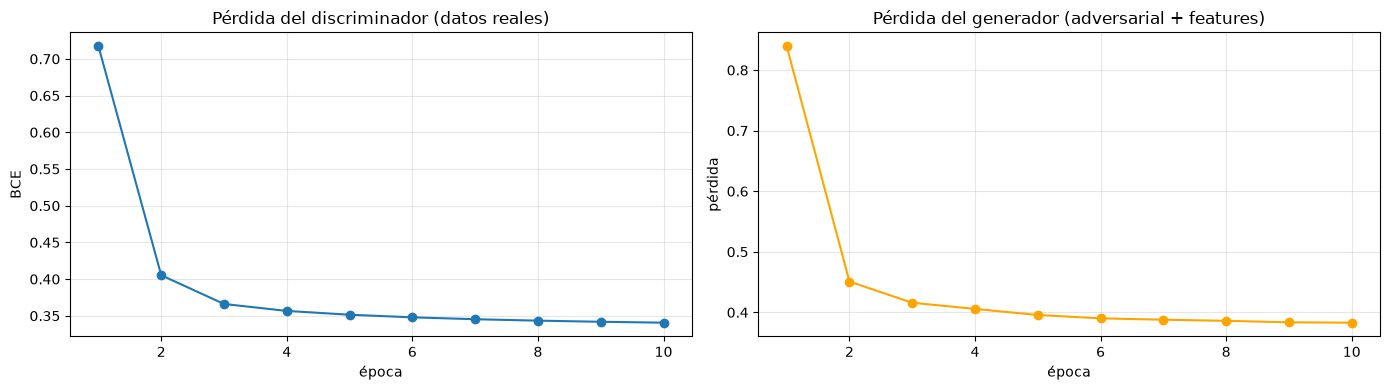

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(
    range(1, EPOCAS_GAN + 1),
    historial_gan["discriminador"],
    marker="o",
)
axes[0].set_title("Pérdida del discriminador (datos reales)")
axes[0].set_xlabel("época")
axes[0].set_ylabel("BCE")
axes[0].grid(True, alpha=0.3)
axes[1].plot(
    range(1, EPOCAS_GAN + 1),
    historial_gan["generador"],
    marker="o",
    color="orange",
)
axes[1].set_title("Pérdida del generador (adversarial + features)")
axes[1].set_xlabel("época")
axes[1].set_ylabel("pérdida")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


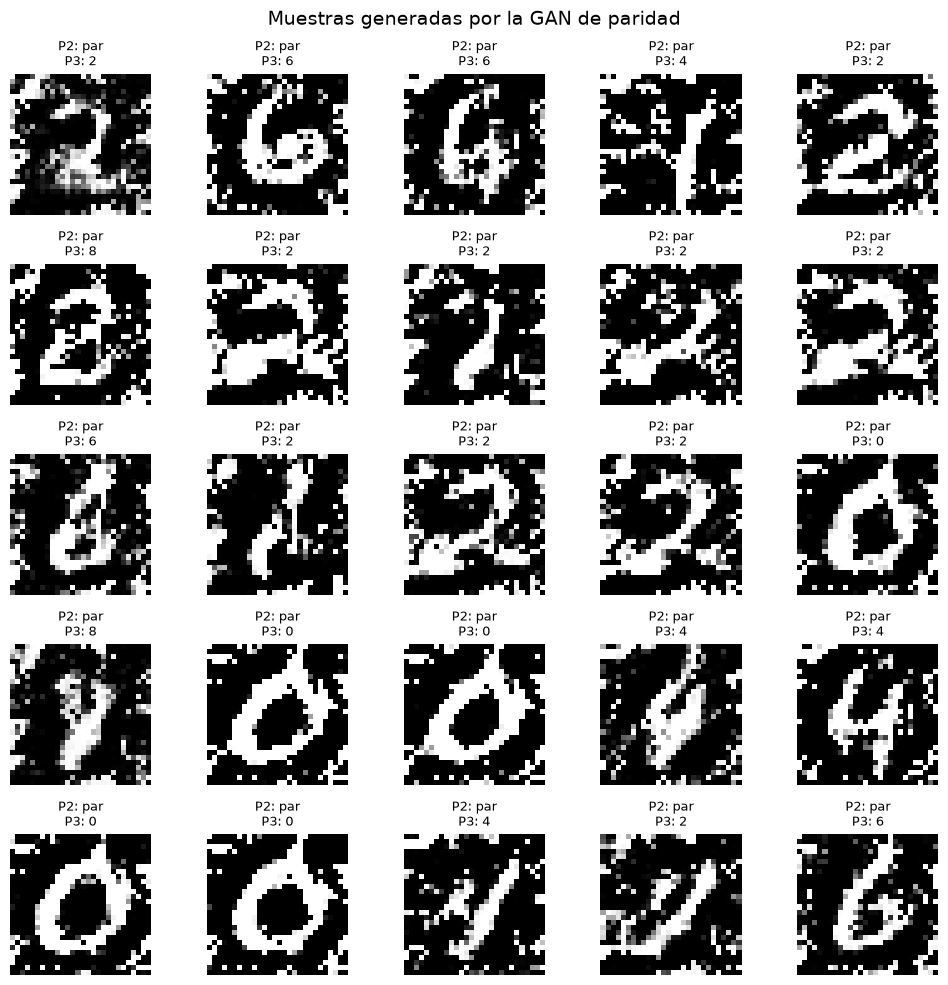

,muestra,P(par) P2,P2,P(par) FT,FT,P(par) GAN-D,dígito P3
0,1,1.0000,par,1.0000,par,0.8917,2
1,2,1.0000,par,1.0000,par,0.9066,6
2,3,1.0000,par,0.9999,par,0.9092,6
3,4,1.0000,par,1.0000,par,0.9189,4
4,5,1.0000,par,0.9999,par,0.8983,2
5,6,1.0000,par,1.0000,par,0.9136,8
6,7,1.0000,par,1.0000,par,0.8915,2
7,8,1.0000,par,0.9999,par,0.9084,2
8,9,1.0000,par,1.0000,par,0.9197,2
9,10,1.0000,par,1.0000,par,0.8983,2


Resumen de las muestras generadas:
  Clasificadas como pares por P2: 100%
  Clasificadas como pares por el modelo fine-tuned: 100%
  Dígitos pares según el modelo de 10 clases: 100%
  Dígitos predichos por P3: {0: 5, 2: 10, 4: 4, 6: 4, 8: 2}


In [15]:
def generar_imagenes(generador, num_muestras=25, semilla=123):
    tf.random.set_seed(semilla)
    ruido = tf.random.normal((num_muestras, 100))
    imagenes = generador(ruido, training=False).numpy()
    return np.clip((imagenes + 1.0) / 2.0, 0.0, 1.0)


imagenes_generadas = generar_imagenes(generador, num_muestras=25)

prob_p2_gen = modelo_p2.predict(
    imagenes_generadas[..., 0], verbose=0
).ravel()
prob_ft_gen = modelo_ft_pre_gan.predict(
    imagenes_generadas, verbose=0
).ravel()
prob_d_gen = discriminador_gan.predict(
    imagenes_generadas, verbose=0
).ravel()
digitos_gen = np.argmax(
    modelo_p3.predict(imagenes_generadas, verbose=0), axis=1
)

pred_p2_gen = (prob_p2_gen >= 0.5).astype(int)
pred_ft_gen = (prob_ft_gen >= 0.5).astype(int)

fig, axes = plt.subplots(5, 5, figsize=(10, 10))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(imagenes_generadas[i, ..., 0], cmap="gray")
    ax.set_title(
        f"P2: {'par' if pred_p2_gen[i] else 'impar'}\n"
        f"P3: {digitos_gen[i]}",
        fontsize=9,
    )
    ax.axis("off")
fig.suptitle("Muestras generadas por la GAN de paridad", fontsize=14)
plt.tight_layout()
plt.show()

tabla_generadas = pd.DataFrame({
    "muestra": np.arange(1, len(imagenes_generadas) + 1),
    "P(par) P2": prob_p2_gen.round(4),
    "P2": np.where(pred_p2_gen == 1, "par", "impar"),
    "P(par) FT": prob_ft_gen.round(4),
    "FT": np.where(pred_ft_gen == 1, "par", "impar"),
    "P(par) GAN-D": prob_d_gen.round(4),
    "dígito P3": digitos_gen,
})
display(tabla_generadas)

print("Resumen de las muestras generadas:")
print(f"  Clasificadas como pares por P2: {pred_p2_gen.mean():.0%}")
print(
    "  Clasificadas como pares por el modelo fine-tuned: "
    f"{pred_ft_gen.mean():.0%}"
)
print(
    "  Dígitos pares según el modelo de 10 clases: "
    f"{np.mean(digitos_gen % 2 == 0):.0%}"
)
conteo_digitos = {
    int(digito): int(cantidad)
    for digito, cantidad in zip(*np.unique(digitos_gen, return_counts=True))
}
print("  Dígitos predichos por P3:", conteo_digitos)


### Justificación de los números generados
De las 25 muestras generadas:

- El 100% son clasificadas como pares por el modelo de la Práctica 2, que no participó en la GAN.
- El 100% son clasificadas como pares por el modelo fine-tuned antes de la GAN.
- El modelo original de la Práctica 3 (10 clases) identifica mayoritariamente dígitos pares: [0, 2, 4, 6, 8]. No aparece ningún dígito impar. En total, el 100% de las muestras se clasifican como un dígito par.

La probabilidad media de "par" que asigna el discriminador de la GAN a sus propias muestras es 90.25%. Esto es coherente con el objetivo del generador: maximizar la salida "par" del discriminador.

Visualmente se observan dígitos 0, 2, 4, 6 y 8 con trazos gruesos y algo de ruido de fondo. La calidad no es la de un generador convolucional moderno porque se parte de la MLP de la Práctica 5, pero la paridad se impone de forma clara. Algunas muestras tienen ruido o trazos irregulares, lo que refleja las limitaciones del generador; aun así, todas las muestras de esta ejecución se clasifican como pares.

## 3. Evaluación del discriminador de la GAN en MNIST

Ahora tomamos el **discriminador de la GAN** (el modelo de paridad que se ha seguido entrenando durante la GAN) y lo evaluamos sobre el conjunto de test de MNIST. Lo comparamos con:

- El modelo guardado de la **Práctica 2**.
- El modelo de la **Práctica 3** original, mapeando sus 10 clases a paridad.
- El modelo **fine-tuned** antes de la GAN.

Además, como referencia, reutilizamos el **discriminador real/falso de la Práctica 5** como extractor de características y entrenamos una regresión logística para paridad.


In [17]:
prob_gan_d = discriminador_gan.predict(
    x_test_3d, batch_size=256, verbose=0
).ravel()

tabla_parte3 = pd.DataFrame([
    evaluar_binario("P2 (MLP, guardado)", y_test_bin, prob_p2),
    evaluar_binario(
        "P3 base (10 clases → suma de pares)", y_test_bin, prob_p3_par
    ),
    evaluar_binario("P3 fine-tuned (pre-GAN)", y_test_bin, prob_ft),
    evaluar_binario(
        "Discriminador GAN (post-GAN)", y_test_bin, prob_gan_d
    ),
])
tabla_parte3["parámetros"] = [
    modelo_p2.count_params(),
    modelo_p3.count_params(),
    modelo_ft.count_params(),
    discriminador_gan.count_params(),
]

print("Comparación final en el conjunto de test")
display(formatear_tabla(tabla_parte3))


Comparación final en el conjunto de test


,modelo,accuracy,errores,precision,recall,f1,auc,parámetros
0,"P2 (MLP, guardado)",98.92 %,108,98.67 %,99.15 %,98.91 %,99.9 %,"533,505"
1,P3 base (10 clases → suma de pares),99.55 %,45,99.47 %,99.61 %,99.54 %,99.98 %,"842,154"
2,P3 fine-tuned (pre-GAN),99.57 %,43,99.51 %,99.61 %,99.56 %,99.99 %,"839,841"
3,Discriminador GAN (post-GAN),99.55 %,45,99.49 %,99.59 %,99.54 %,99.98 %,"839,841"


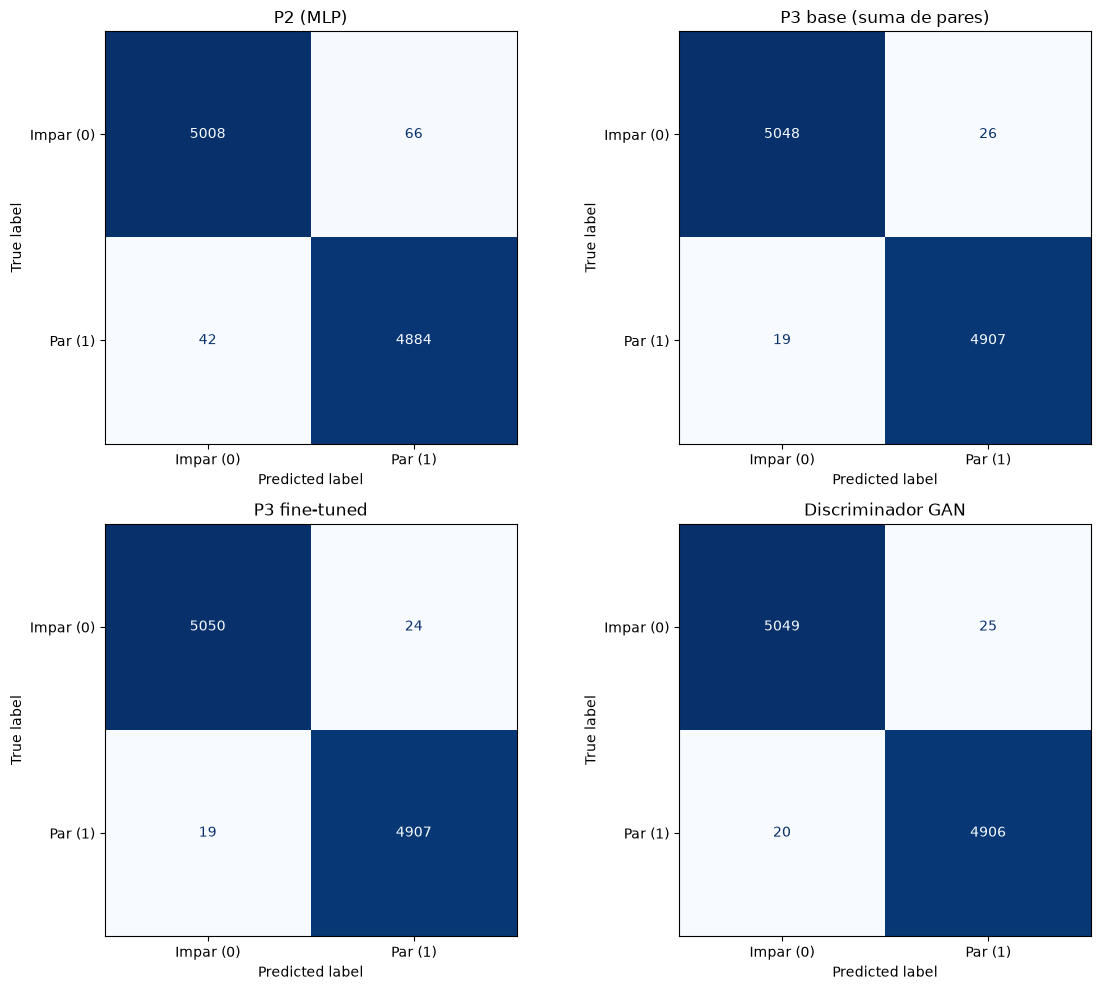

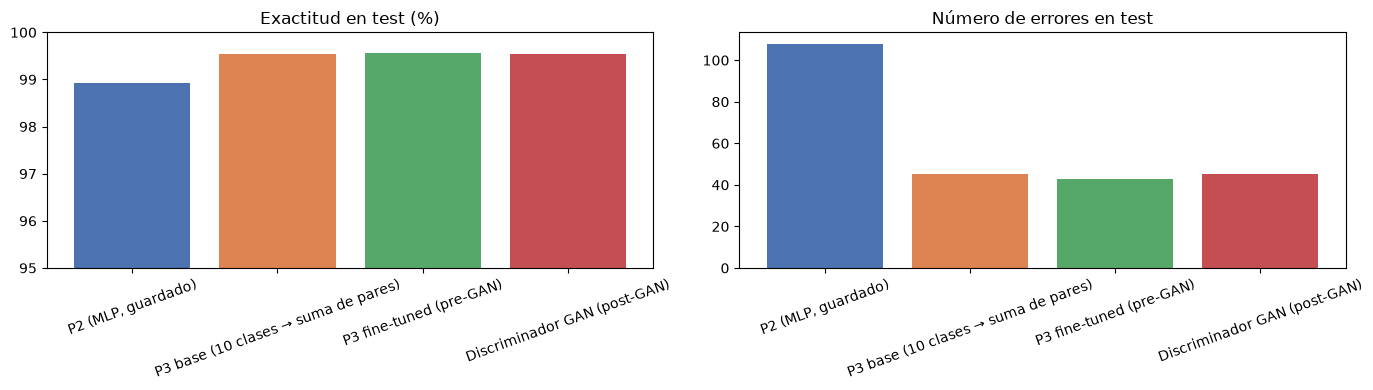

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (nombre, probabilidad) in zip(
    axes.flatten(),
    [
        ("P2 (MLP)", prob_p2),
        ("P3 base (suma de pares)", prob_p3_par),
        ("P3 fine-tuned", prob_ft),
        ("Discriminador GAN", prob_gan_d),
    ],
):
    prediccion = (probabilidad >= 0.5).astype(int)
    matriz = confusion_matrix(y_test_bin, prediccion)
    ConfusionMatrixDisplay(
        matriz, display_labels=["Impar (0)", "Par (1)"]
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colores = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]
axes[0].bar(
    tabla_parte3["modelo"],
    tabla_parte3["accuracy"] * 100,
    color=colores,
)
axes[0].set_title("Exactitud en test (%)")
axes[0].set_ylim(95.0, 100.0)
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(
    tabla_parte3["modelo"],
    tabla_parte3["errores"],
    color=colores,
)
axes[1].set_title("Número de errores en test")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


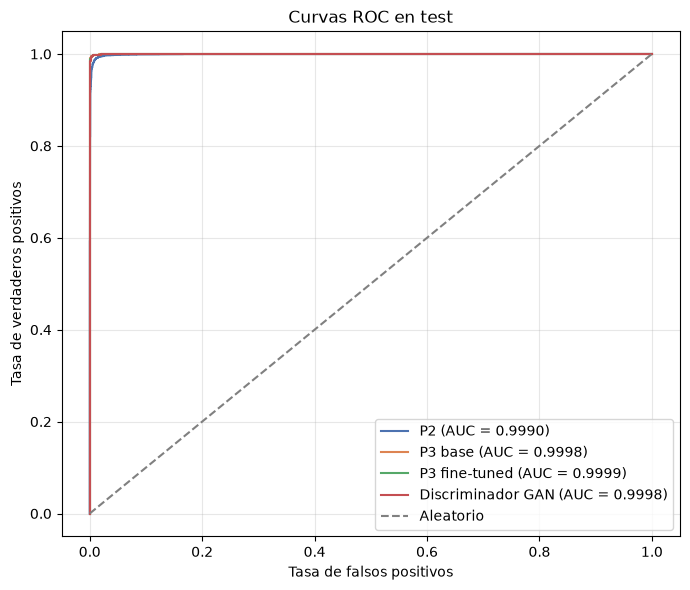

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, probabilidad, color in [
    ("P2", prob_p2, "#4C72B0"),
    ("P3 base", prob_p3_par, "#DD8452"),
    ("P3 fine-tuned", prob_ft, "#55A868"),
    ("Discriminador GAN", prob_gan_d, "#C44E52"),
]:
    fpr, tpr, _ = roc_curve(y_test_bin, probabilidad)
    auc = roc_auc_score(y_test_bin, probabilidad)
    ax.plot(
        fpr,
        tpr,
        color=color,
        label=f"{nombre} (AUC = {auc:.4f})",
    )
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aleatorio")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.set_title("Curvas ROC en test")
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 3.1. Referencia: discriminador real/falso de la Práctica 5

El discriminador guardado en `discriminator.pth` no es un clasificador de paridad: fue entrenado para distinguir imágenes reales de imágenes generadas. Para poder compararlo, se elimina su capa de salida y se usan sus 256 características intermedias como entrada de una regresión logística entrenada para predecir la paridad. Es una comparación de *transferencia de características*, no un uso directo del discriminador como clasificador de paridad.


In [20]:
class DiscriminadorP5(nn.Module):
    def __init__(self, img_dim=28 * 28):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(img_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.net(x)

    def caracteristicas(self, x):
        return self.net[:4](x)


discriminador_p5 = DiscriminadorP5().to(DISPOSITIVO)
discriminador_p5.load_state_dict(
    torch.load(RUTA_P5 / "discriminator.pth", map_location=DISPOSITIVO)
)
discriminador_p5.eval()


def extraer_caracteristicas_p5(imagenes, tamano_lote=512):
    tensor = torch.tensor(
        imagenes, dtype=torch.float32, device=DISPOSITIVO
    ).reshape(-1, 28 * 28)
    tensor = tensor * 2.0 - 1.0
    caracteristicas = []
    with torch.no_grad():
        for inicio in range(0, len(tensor), tamano_lote):
            lote = tensor[inicio : inicio + tamano_lote]
            caracteristicas.append(
                discriminador_p5.caracteristicas(lote).cpu().numpy()
            )
    return np.concatenate(caracteristicas, axis=0)


X_train_p5 = extraer_caracteristicas_p5(x_train)
X_test_p5 = extraer_caracteristicas_p5(x_test)

clasificador_p5 = LogisticRegression(max_iter=1000)
clasificador_p5.fit(X_train_p5, y_train_bin)
prob_p5 = clasificador_p5.predict_proba(X_test_p5)[:, 1]

fila_p5 = evaluar_binario(
    "P5 D real/falso + regresión logística", y_test_bin, prob_p5
)
tabla_p5 = pd.DataFrame([fila_p5])
tabla_p5["parámetros"] = "512·784 + 256·512 + logreg"

print("Referencia: reutilización del discriminador real/falso de la Práctica 5")
display(formatear_tabla(tabla_p5))


Referencia: reutilización del discriminador real/falso de la Práctica 5


,modelo,accuracy,errores,precision,recall,f1,auc,parámetros
0,P5 D real/falso + regresión logística,96.05 %,395,96.17 %,95.8 %,95.98 %,99.27 %,512·784 + 256·512 + logreg


### Conclusiones finales
1. **Ajuste fino (parte 1)**. El modelo de P3 adaptado a paridad alcanza 99.57% de exactitud en test (43 errores), frente al 98.92% del modelo de P2 (108 errores). La mejora es de 0.65 puntos porcentuales y 65 errores menos. El mapeo directo del modelo de 10 clases de P3 obtiene 99.55% (45 errores), por lo que el fine-tuning queda en un nivel equivalente o ligeramente superior, pero con una salida binaria más directa.

2. **GAN de paridad (parte 2)**. Al usar el clasificador de paridad como discriminador, el generador aprende a producir dígitos que el discriminador clasifica como pares. En las 25 muestras generadas, el 100% son pares para P2, el 100% para el modelo fine-tuned y el 100% para el modelo de 10 clases de P3. Se obtienen sobre todo 0, 2, 4, 6 y 8, con ruido y trazos irregulares.

3. **Discriminador de la GAN (parte 3)**. Tras el entrenamiento adversarial, el discriminador mantiene 99.55% de exactitud (45 errores), prácticamente igual que el modelo fine-tuned antes de la GAN (99.57%, 43 errores) y mejor que P2. Esto indica que el entrenamiento de la GAN no ha degradado su capacidad de clasificar paridad, gracias a que se ha seguido entrenando con datos reales, con una tasa de aprendizaje baja y label smoothing.

4. **Referencia de la Práctica 5**. El discriminador real/falso de P5, reutilizado como extractor de características y combinado con una regresión logística, alcanza 96.05% (395 errores). Está por debajo de los modelos especializados en paridad, lo que confirma que sus representaciones están orientadas a distinguir real/falso y no a la paridad.

## Limitaciones y posibles mejoras

- El generador es la MLP de la Práctica 5 (100 → 256 → 512 → 784). Para mejorar la calidad visual se podría usar un generador convolucional (DCGAN) o una GAN condicional que reciba además el dígito objetivo.
- El entrenamiento de la GAN se ha limitado a 10 épocas para que el cuaderno sea ejecutable en un tiempo razonable. Más épocas, un generador mayor o un ajuste más fino de las tasas de aprendizaje podrían reducir el ruido de fondo.
- El discriminador se ha entrenado solo con imágenes reales para no perder su capacidad de paridad. Una alternativa sería alternar actualizaciones con imágenes reales y generadas, usando un peso pequeño para las generadas, o añadir un segundo discriminador de realismo.
- La conclusión principal se mantiene: el modelo de P3 fine-tuned es un buen clasificador de paridad y, usado como discriminador, transforma una GAN de dígitos en un generador de números pares.
